In [1]:
import json
import urllib.request
from urllib.parse import quote, urlsplit, urlunsplit
import pandas as pd
import matplotlib.pyplot as plt

# Adresse du serveur HDFS
HDFS_BASE = "http://host.docker.internal:9870/webhdfs/v1"

# Liste des villes
villes = {
    "France": "Paris",
    "Spain": "Seville",
    "United Arab Emirates": "Dubai",
    "Iceland": "Reykjavik",
    "New Zealand": "Wellington"
}

# Fonction de lecture HDFS
def lire_hdfs(path):

    url = (
        HDFS_BASE
        + quote(path, safe="/")
        + "?op=OPEN&user.name=root&noredirect=true"
    )

    with urllib.request.urlopen(url, timeout=15) as response:
        resultat = json.load(response)

    adresse = urlsplit(resultat["Location"])

    destination = urlunsplit((
        adresse.scheme,
        f"host.docker.internal:{adresse.port}",
        adresse.path,
        adresse.query,
        adresse.fragment
    ))

    with urllib.request.urlopen(destination, timeout=15) as response:
        return response.read().decode("utf-8")


# Récupération des messages météo
donnees = []

for pays, ville in villes.items():

    chemin = f"/hdfs-data/{pays}/{ville}/alerts.json"

    contenu = lire_hdfs(chemin)

    for ligne in contenu.splitlines():

        if ligne.strip():
            donnees.append(json.loads(ligne))

# Conversion en DataFrame Pandas
df = pd.DataFrame(donnees)

print("Données HDFS récupérées !")
print("Nombre total de messages :", len(df))

display(df.head())

Matplotlib created a temporary cache directory at /tmp/matplotlib-f8rlkkfb because the default path (/tmp/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Données HDFS récupérées !
Nombre total de messages : 10


,event_time,city,country,temperature,windspeed,weather_code,wind_alert_level,heat_alert_level,_kafka_partition,_kafka_offset
0,2026-11-10T17:02:24.004+01:00,Paris,France,12.7,1.34,3,level_0,level_0,0,0
1,2026-11-10T17:02:58.341+01:00,Paris,France,12.7,1.34,3,level_0,level_0,0,5
2,2026-11-10T17:02:25.081+01:00,Seville,Spain,20.3,4.88,80,level_0,level_0,0,1
3,2026-11-10T17:02:59.078+01:00,Seville,Spain,20.3,4.88,80,level_0,level_0,0,6
4,2026-11-10T17:02:26.101+01:00,Dubai,United Arab Emirates,30.0,2.78,0,level_0,level_1,0,2


In [2]:
# Vérification des colonnes
print("Colonnes disponibles :")
print(df.columns.tolist())

# Conversion des valeurs numériques
df["temperature"] = pd.to_numeric(
    df["temperature"], errors="coerce"
)

df["windspeed"] = pd.to_numeric(
    df["windspeed"], errors="coerce"
)

df["weather_code"] = pd.to_numeric(
    df["weather_code"], errors="coerce"
)

print("\nDonnées préparées !")

display(df[[
    "city",
    "temperature",
    "windspeed",
    "weather_code",
    "wind_alert_level",
    "heat_alert_level"
]].head())

Colonnes disponibles :
['event_time', 'city', 'country', 'temperature', 'windspeed', 'weather_code', 'wind_alert_level', 'heat_alert_level', '_kafka_partition', '_kafka_offset']

Données préparées !


,city,temperature,windspeed,weather_code,wind_alert_level,heat_alert_level
0,Paris,12.7,1.34,3,level_0,level_0
1,Paris,12.7,1.34,3,level_0,level_0
2,Seville,20.3,4.88,80,level_0,level_0
3,Seville,20.3,4.88,80,level_0,level_0
4,Dubai,30.0,2.78,0,level_0,level_1


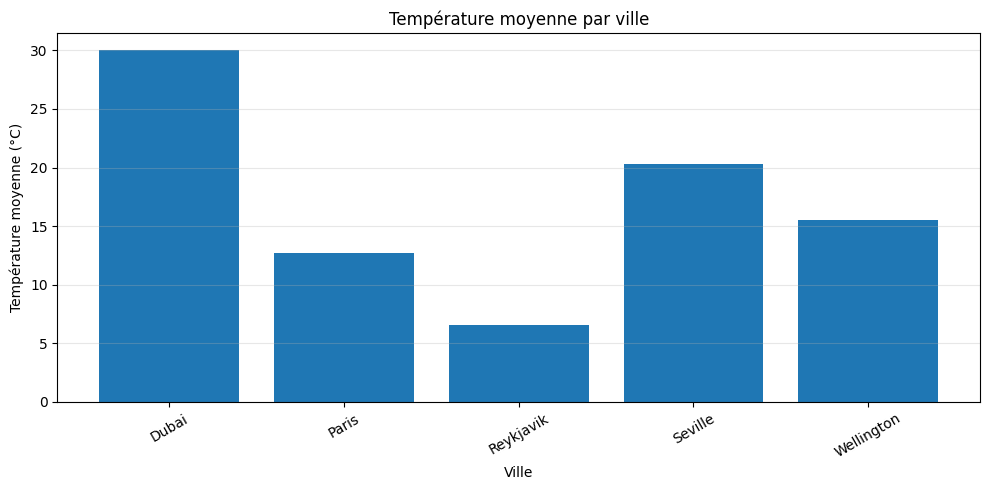

In [3]:
temperature = df.groupby("city")["temperature"].mean()

plt.figure(figsize=(10, 5))

plt.bar(temperature.index, temperature.values)

plt.title("Température moyenne par ville")
plt.xlabel("Ville")
plt.ylabel("Température moyenne (°C)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

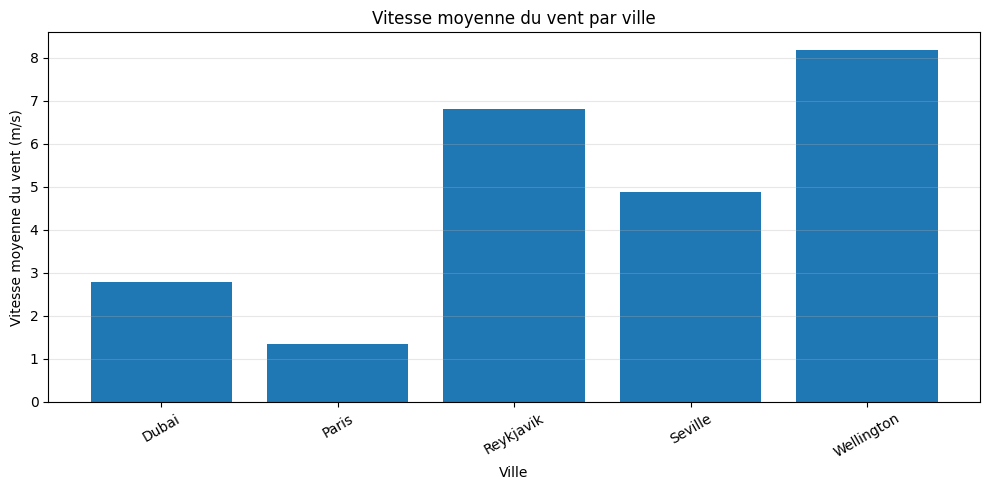

In [4]:
vent = df.groupby("city")["windspeed"].mean()

plt.figure(figsize=(10, 5))

plt.bar(vent.index, vent.values)

plt.title("Vitesse moyenne du vent par ville")
plt.xlabel("Ville")
plt.ylabel("Vitesse moyenne du vent (m/s)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

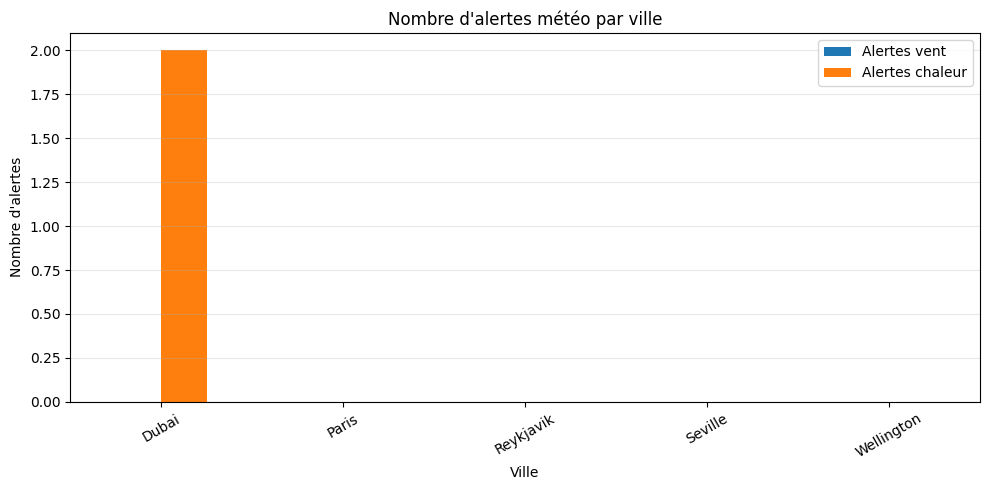

In [5]:
# Identifier les alertes de niveaux 1 et 2
df["alerte_vent"] = (
    df["wind_alert_level"]
    .isin(["level_1", "level_2"])
    .astype(int)
)

df["alerte_chaleur"] = (
    df["heat_alert_level"]
    .isin(["level_1", "level_2"])
    .astype(int)
)

# Calcul du nombre d'alertes
alertes = df.groupby("city")[
    ["alerte_vent", "alerte_chaleur"]
].sum()

# Graphique
ax = alertes.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Nombre d'alertes météo par ville")
plt.xlabel("Ville")
plt.ylabel("Nombre d'alertes")
plt.xticks(rotation=30)
plt.legend(["Alertes vent", "Alertes chaleur"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

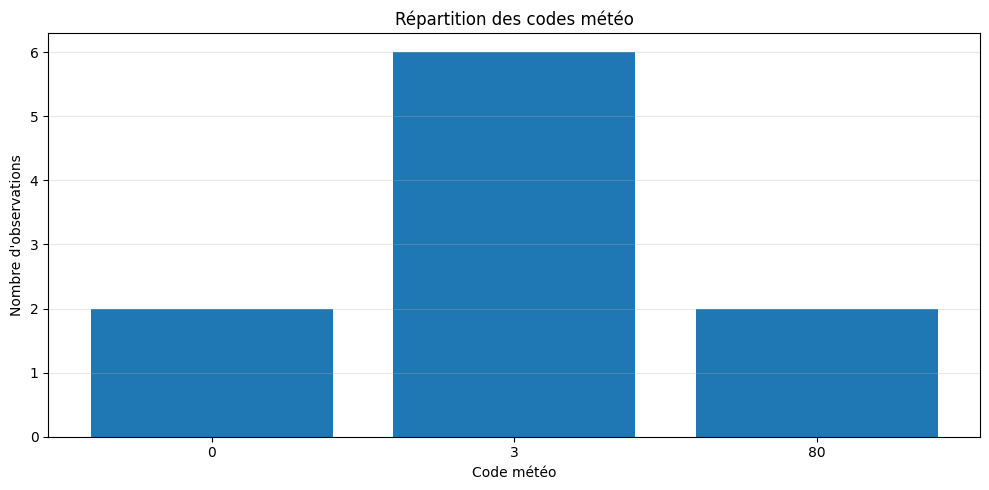

In [6]:
# Compter les codes météo
codes = df["weather_code"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(codes.index.astype(str), codes.values)

plt.title("Répartition des codes météo")
plt.xlabel("Code météo")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

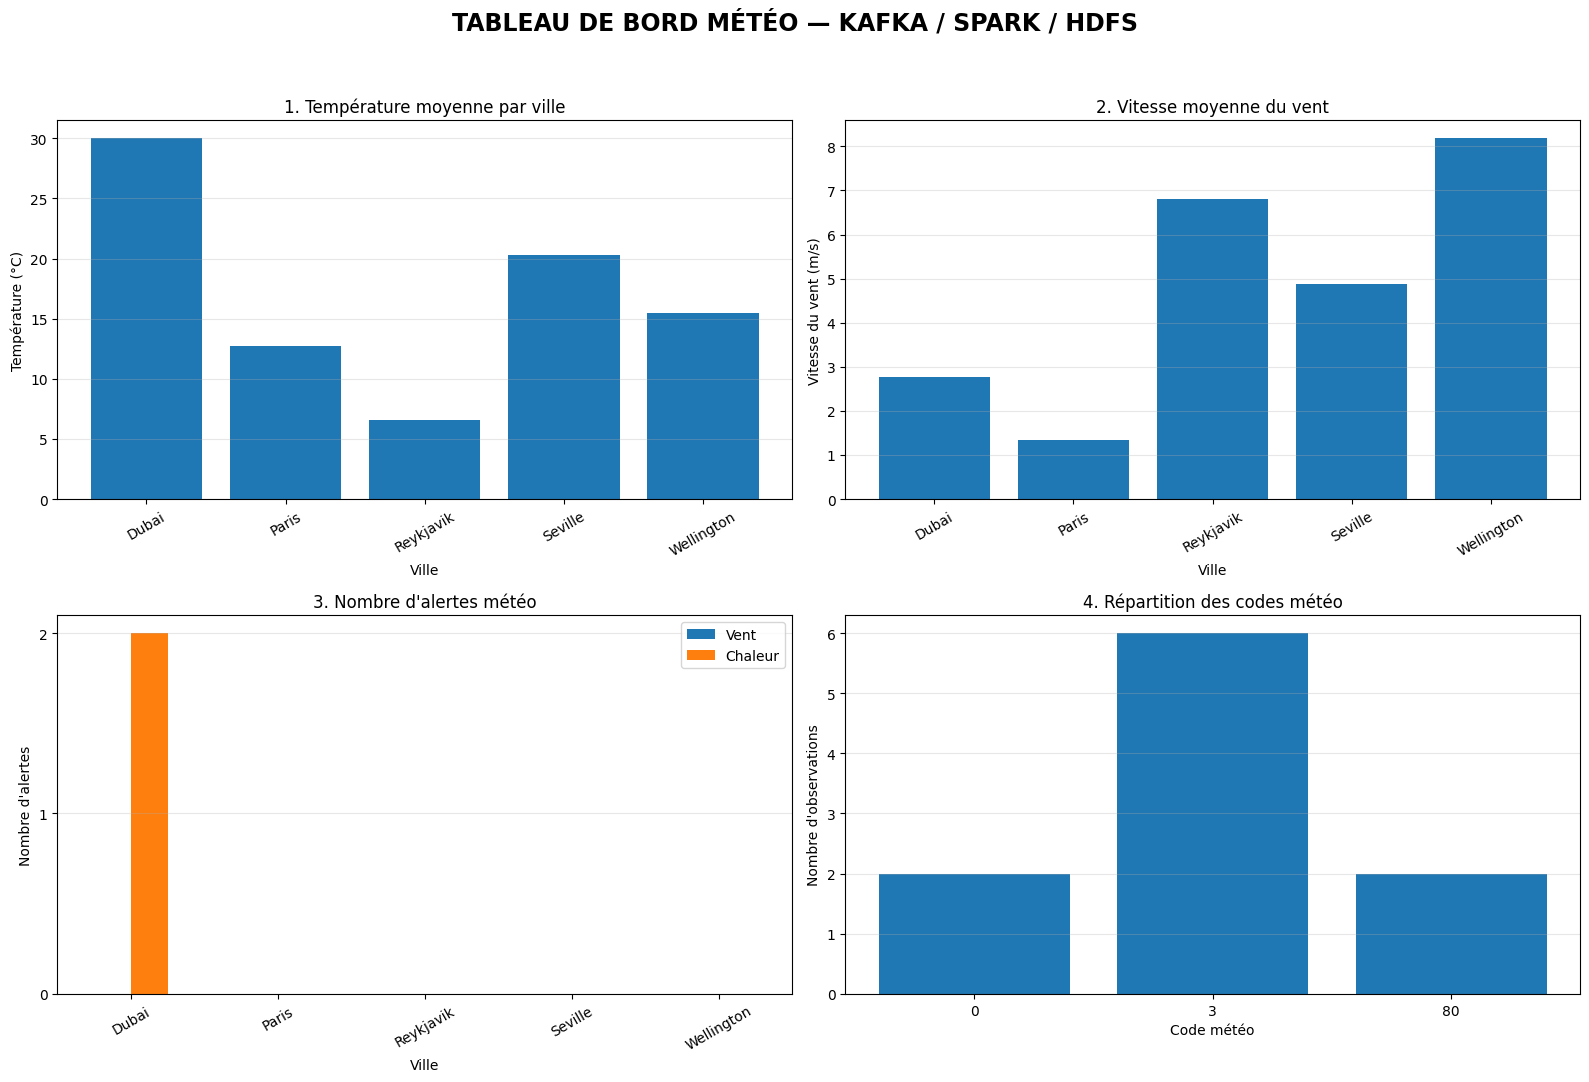

Tableau de bord météo généré avec succès !
Nombre de messages analysés : 10


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Préparation des données
df["temperature"] = pd.to_numeric(df["temperature"], errors="coerce")
df["windspeed"] = pd.to_numeric(df["windspeed"], errors="coerce")
df["weather_code"] = pd.to_numeric(df["weather_code"], errors="coerce")

# Création d'une seule figure divisée en 4 graphiques
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    "TABLEAU DE BORD MÉTÉO — KAFKA / SPARK / HDFS",
    fontsize=17,
    fontweight="bold"
)

# ==================================================
# GRAPHIQUE 1 : TEMPÉRATURE MOYENNE
# ==================================================

temperature = df.groupby("city")["temperature"].mean()

axes[0, 0].bar(
    temperature.index,
    temperature.values
)

axes[0, 0].set_title("1. Température moyenne par ville")
axes[0, 0].set_xlabel("Ville")
axes[0, 0].set_ylabel("Température (°C)")
axes[0, 0].tick_params(axis="x", rotation=30)
axes[0, 0].grid(axis="y", alpha=0.3)


# ==================================================
# GRAPHIQUE 2 : VITESSE MOYENNE DU VENT
# ==================================================

vent = df.groupby("city")["windspeed"].mean()

axes[0, 1].bar(
    vent.index,
    vent.values
)

axes[0, 1].set_title("2. Vitesse moyenne du vent")
axes[0, 1].set_xlabel("Ville")
axes[0, 1].set_ylabel("Vitesse du vent (m/s)")
axes[0, 1].tick_params(axis="x", rotation=30)
axes[0, 1].grid(axis="y", alpha=0.3)


# ==================================================
# GRAPHIQUE 3 : NOMBRE D'ALERTES
# ==================================================

df["alerte_vent"] = (
    df["wind_alert_level"]
    .isin(["level_1", "level_2"])
    .astype(int)
)

df["alerte_chaleur"] = (
    df["heat_alert_level"]
    .isin(["level_1", "level_2"])
    .astype(int)
)

alertes = df.groupby("city")[
    ["alerte_vent", "alerte_chaleur"]
].sum()

alertes.plot(
    kind="bar",
    ax=axes[1, 0]
)

axes[1, 0].set_title("3. Nombre d'alertes météo")
axes[1, 0].set_xlabel("Ville")
axes[1, 0].set_ylabel("Nombre d'alertes")
axes[1, 0].tick_params(axis="x", rotation=30)
axes[1, 0].legend(["Vent", "Chaleur"])
axes[1, 0].grid(axis="y", alpha=0.3)


# ==================================================
# GRAPHIQUE 4 : CODES MÉTÉO
# ==================================================

codes = df["weather_code"].value_counts().sort_index()

axes[1, 1].bar(
    codes.index.astype(str),
    codes.values
)

axes[1, 1].set_title("4. Répartition des codes météo")
axes[1, 1].set_xlabel("Code météo")
axes[1, 1].set_ylabel("Nombre d'observations")
axes[1, 1].grid(axis="y", alpha=0.3)


# ==================================================
# AFFICHAGE FINAL
# ==================================================
from matplotlib.ticker import MaxNLocator

axes[1, 0].yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()

print("Tableau de bord météo généré avec succès !")
print("Nombre de messages analysés :", len(df))